# Part 0 — TinyStories and tokenization

In this notebook you will:

1. download the dataset,
2. get familiar with the stories,
3. split the stories into a training and a validation set,
4. learn how a tokenizer converts between text and integers, and tokenize the
   dataset, and
5. build the Dataset and DataLoaders for next-token prediction.

In [2]:
%load_ext autoreload
%autoreload 2

import json
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from tokenizers import Tokenizer

import assignment3 as a3

TEXT_PATH = "./data/TinyStoriesV2-GPT4-train.txt"
print(f"PyTorch: {torch.__version__}")

PyTorch: 2.14.1+cu126


## 1. Download the dataset

In this assignment, you will train a small GPT-style model on
[TinyStories](https://arxiv.org/abs/2305.07759), a dataset of short stories
that only use words a 3–4-year-old child would understand. 

The dataset is hosted on [Hugging Face](https://huggingface.co/datasets/roneneldan/TinyStories).
The original training file has about 2.2 GB of text. We only use its first
500 MB (about 610,000 stories). Run the following cell to download it into `data/`.

In [3]:
# Check if the dataset exists, and download it if it doesn't
# We only download the first 500MB
if not os.path.exists(TEXT_PATH):
    a3.download_tinystories(TEXT_PATH)

print("Dataset ready at:", TEXT_PATH)

Dataset ready at: ./data/TinyStoriesV2-GPT4-train.txt


## 2. Get familiar with the dataset

The file is plain text, and the stories are separated by the marker
`<|endoftext|>`. Let's read the first 10 MB of the file and look at a random
story.

In [4]:
with open(TEXT_PATH, encoding="utf-8") as f:
    sample_text = f.read(10_000_000)
stories = sample_text.split("<|endoftext|>")[:-1]  # the last story may be cut off
stories = [story.strip() for story in stories]
print(f"Stories in the first 10 MB: {len(stories):,}")

Stories in the first 10 MB: 12,099


In [5]:
# display a random story
i = np.random.randint(len(stories))
print(f"Story {i}:\n")
print(stories[i])

Story 5972:

Once upon a time, there was a wise old owl. The owl loved to travel far and wide. One day, the owl found a mystery box in the woods.
The wise owl was very curious about the mystery box. He tried to open it, but it was locked. The owl decided to travel with the mystery box to find the key.
As the wise owl traveled, he met a big bear. The bear said, "I have the key to the mystery box!" The wise owl was happy, but the bear did not want to share the key. The wise owl tried to be nice, but the bear was mean.
In the end, the wise owl could not open the mystery box. He was very sad and went back home. The wise owl learned that sometimes, you cannot solve every mystery.


The stories use simple words, but they still have dialogue, characters that
appear several times, and a beginning, middle, and end. The histogram below
shows how long the stories are.

Mean length: 162 words


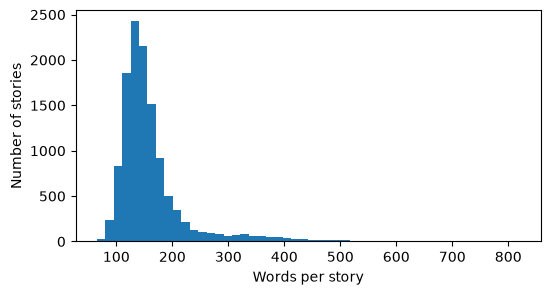

In [6]:
story_lengths = [len(story.split()) for story in stories]
print(f"Mean length: {np.mean(story_lengths):.0f} words")

plt.figure(figsize=(6, 3))
plt.hist(story_lengths, bins=50)
plt.xlabel("Words per story")
plt.ylabel("Number of stories")
plt.show()

## 3. Split the dataset

We will split the dataset into a training set and a validation set. 

**Your task here:**

Complete `split_stories()` in [`assignment3/data.py`](assignment3/data.py)
(1 mark). 

You can follow these steps:
1. Read the whole text file and split it into stories by `"<|endoftext|>"`.
   Strip the whitespace around each story and skip empty stories.
2. Split the stories into two sets, so that every story is in exactly one set:
   - validation set: `int(num_stories * val_fraction)` stories,
   - training set: the rest of the stories.
3. Save each set as `train.txt` and `val.txt` in `data_dir`, in
   the same format as the original file: every story is followed by
   `<|endoftext|>` on its own line.

   ```
   Once upon a time, ...
   <|endoftext|>
   One day, ...
   <|endoftext|>
   ```

Run the cell below once to split the dataset, and the cell after it to check
the files. The cell below does not overwrite existing files; delete them if you
change your code and want to run it again.

In [7]:
DATA_DIR = "./data"
if not os.path.exists(os.path.join(DATA_DIR, "val.txt")):
    a3.split_stories(TEXT_PATH, DATA_DIR)
print("Done")

Done


In [8]:
# Sanity check the split files
num_stories = {}
for split in ["train", "val"]:
    with open(os.path.join(DATA_DIR, f"{split}.txt"), encoding="utf-8") as f:
        split_text = f.read()
    assert split_text.rstrip().endswith("<|endoftext|>"), \
        f"every story in {split}.txt, including the last one, should be followed by <|endoftext|> " \
        "(if you changed your code, delete the old .txt files and run the cell above again)"
    num_stories[split] = split_text.count("<|endoftext|>")

total = sum(num_stories.values())
for split, n in num_stories.items():
    print(f"{split}: {n:,} stories ({n / total:.1%})")
print(f"total: {total:,} stories")

train: 579,664 stories (95.0%)
val: 30,508 stories (5.0%)
total: 610,172 stories


## 4. Tokenization

### Byte-pair encoding (BPE)

**Byte-pair encoding (BPE)** is a subword tokenization algorithm used by many language models, including GPT models. It starts with single characters as tokens, then repeatedly finds the pair of neighbouring tokens that appears most often in the training text and **merges** this pair into a new token. Each merge adds one token to the vocabulary, and BPE stops when the vocabulary reaches the target size.

The following cell runs a few BPE merges on a tiny corpus and prints the words after every merge. To learn more about BPE, see [Byte-Pair Encoding tokenization](https://huggingface.co/learn/llm-course/chapter6/5) in the Hugging Face LLM Course.

In [9]:
corpus = "the cat sat on the mat . the cat ate the rat ."
words = [list(word) for word in corpus.split()]  # every word starts as single characters

for step in range(4):
    # count every pair of neighbouring tokens
    pair_counts = {}
    for word in words:
        for pair in zip(word[:-1], word[1:]):
            pair_counts[pair] = pair_counts.get(pair, 0) + 1
    best_pair = max(pair_counts, key=pair_counts.get)

    # merge every occurrence of the most frequent pair
    merged_words = []
    for word in words:
        merged_word = []
        i = 0
        while i < len(word):
            if i < len(word) - 1 and (word[i], word[i + 1]) == best_pair:
                merged_word.append(word[i] + word[i + 1])
                i += 2
            else:
                merged_word.append(word[i])
                i += 1
        merged_words.append(merged_word)
    words = merged_words

    print(f"merge {step + 1}: {best_pair} appears {pair_counts[best_pair]} times")
    print("   ", words)

merge 1: ('a', 't') appears 6 times
    [['t', 'h', 'e'], ['c', 'at'], ['s', 'at'], ['o', 'n'], ['t', 'h', 'e'], ['m', 'at'], ['.'], ['t', 'h', 'e'], ['c', 'at'], ['at', 'e'], ['t', 'h', 'e'], ['r', 'at'], ['.']]
merge 2: ('t', 'h') appears 4 times
    [['th', 'e'], ['c', 'at'], ['s', 'at'], ['o', 'n'], ['th', 'e'], ['m', 'at'], ['.'], ['th', 'e'], ['c', 'at'], ['at', 'e'], ['th', 'e'], ['r', 'at'], ['.']]
merge 3: ('th', 'e') appears 4 times
    [['the'], ['c', 'at'], ['s', 'at'], ['o', 'n'], ['the'], ['m', 'at'], ['.'], ['the'], ['c', 'at'], ['at', 'e'], ['the'], ['r', 'at'], ['.']]
merge 4: ('c', 'at') appears 2 times
    [['the'], ['cat'], ['s', 'at'], ['o', 'n'], ['the'], ['m', 'at'], ['.'], ['the'], ['cat'], ['at', 'e'], ['the'], ['r', 'at'], ['.']]


### Our tokenizer

We have trained a BPE tokenizer with 4,096 tokens on TinyStories. The result is saved in `data/tokenizer.json`. The json file contains the vocabulary and the merges. You can use the following code to inspect the file.

A few things to notice:

- Token 0, `<|endoftext|>`, is a special token that marks the end of a story.
  We put it after every story in the dataset, so that the model also learns
  when to finish a story.
- Tokens 1 to 256 are the 256 possible bytes.
- The merged tokens start at ID 257, one per merge. For example, the first
  merge `["Ġ", "t"]` created token 257, `"Ġt"`.
- `Ġ` stands for a space (and `Ċ` for a newline), which is how GPT-2 shows
  these bytes inside tokens. Most words come with the space in front of them. For example, `ĠLily` (" Lily") and `Lily` are different tokens.

In [10]:
TOKENIZER_PATH = "./data/tokenizer.json"
with open(TOKENIZER_PATH, encoding="utf-8") as f:
    tokenizer_json = json.load(f)

# Structure of the file
print("Top-level keys:", list(tokenizer_json.keys()))
print("Keys under 'model':", list(tokenizer_json["model"].keys()))
print("Model type:", tokenizer_json["model"]["type"])
vocab = tokenizer_json["model"]["vocab"]  # token -> ID
merges = tokenizer_json["model"]["merges"]
print(f"'vocab' is a {type(vocab).__name__} with {len(vocab)} entries")
print(f"'merges' is a {type(merges).__name__} with {len(merges)} entries")

# Some examples
vocab_items = list(vocab.items())  # [(token, ID), ...]
print("The first 10 entries of vocab:", dict(vocab_items[:10]))
print("Entries 257 to 276 of vocab:", dict(vocab_items[257:277]))
print("The last 10 entries of vocab:", dict(vocab_items[-10:]))

Top-level keys: ['version', 'truncation', 'padding', 'added_tokens', 'normalizer', 'pre_tokenizer', 'post_processor', 'decoder', 'model']
Keys under 'model': ['type', 'dropout', 'unk_token', 'continuing_subword_prefix', 'end_of_word_suffix', 'fuse_unk', 'byte_fallback', 'ignore_merges', 'vocab', 'merges']
Model type: BPE
'vocab' is a dict with 4096 entries
'merges' is a list with 3839 entries
The first 10 entries of vocab: {'<|endoftext|>': 0, '!': 1, '"': 2, '#': 3, '$': 4, '%': 5, '&': 6, "'": 7, '(': 8, ')': 9}
Entries 257 to 276 of vocab: {'Ġt': 257, 'he': 258, 'Ġa': 259, 'Ġs': 260, 'Ġw': 261, 'nd': 262, 'Ġthe': 263, 'ed': 264, 'Ġb': 265, 'Ġto': 266, 'Ġand': 267, 'Ġh': 268, 'Ġf': 269, 'in': 270, 'ĠT': 271, 'Ġwa': 272, 're': 273, 'it': 274, 'ou': 275, 'Ġl': 276}
The last 10 entries of vocab: {'ĠBessie': 4086, 'ĠCo': 4087, 'Ġtightly': 4088, 'Ġolive': 4089, 'drobe': 4090, 'Ġwardrobe': 4091, 'Ġimprove': 4092, 'Ġmay': 4093, 'imney': 4094, 'Ġstickers': 4095}


In practice, instead of reading and processing the tokenizer json file, we can use the [`tokenizers`](https://github.com/huggingface/tokenizers) library to load the tokenizer, and use it to encode and decode the text.

You can use the following code to get familiar with the tokenizer. It encodes a story into a list of token IDs, and decodes the list back to text. 

In [11]:
# initialize the tokenizer from the json file
tokenizer = Tokenizer.from_file(TOKENIZER_PATH)
# the ID of the end-of-text token
end_of_text_id = tokenizer.token_to_id("<|endoftext|>")

text = "Once upon a time, Lily saw a big dog.\nShe said hello."
encoding = tokenizer.encode(text)
print("Tokens:", encoding.tokens)
print("IDs:", encoding.ids)
print(f"{len(text)} characters -> {len(encoding.ids)} tokens")
print("Decoded:", repr(tokenizer.decode(encoding.ids)))

Tokens: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'ĠLily', 'Ġsaw', 'Ġa', 'Ġbig', 'Ġdog', '.', 'Ċ', 'She', 'Ġsaid', 'Ġhello', '.']
IDs: [430, 438, 259, 398, 12, 405, 382, 259, 346, 464, 14, 199, 1373, 325, 2542, 14]
53 characters -> 16 tokens
Decoded: 'Once upon a time, Lily saw a big dog.\nShe said hello.'


### Tokenize the dataset

For pre-training, a common practice is to tokenize the entire dataset once and save the token IDs to a file. Training then only reads the IDs, instead of tokenizing the same text again in every epoch. (When the dataset is small, as in many fine-tuning tasks, it is also fine to tokenize the text inside the Dataset each time a batch is created.)

**Your task here:**

Complete `tokenize_stories()` in [`assignment3/data.py`](assignment3/data.py)
(1 mark). 

This function reads a text file of stories, converts all stories into token
IDs with the tokenizer, and saves them to `tokens_path` as a `.npy` file.
The saved array is **one long 1-D array** with the IDs of all stories in the
file, in order, and the ID of `<|endoftext|>` (which is `0`) after every story.
For example, the story "The cat sat." becomes:

```
tokens:  The   Ġcat   Ġsat   .    <|endoftext|>
IDs:     411   460    1092   14   0
```

The next story starts right after this `0`, so the saved array looks like
`[411, 460, 1092, 14, 0, <IDs of story 2>, 0, <IDs of story 3>, 0, ...]`.

You can follow these steps:
1. Read the text file and split it into stories at `"<|endoftext|>"`.
   Strip the whitespace around each story and skip empty stories.
2. Encode the stories with `tokenizer.encode_batch()`, which is faster than
   calling `tokenizer.encode()` for each story. Encoding all training stories
   at once needs more than 15 GB of memory, so encode them in batches of around
   10,000 stories (e.g., 5,000 to 20,000). Remember to append the ID of
   `<|endoftext|>` after every story.
3. The saved array should be a 1-D NumPy array of type `np.uint16`.
   Convert the IDs of every batch into a NumPy array of type `np.uint16`,
   join all arrays into one 1-D array with `np.concatenate()`, and save it
   with `np.save()`.

Useful documentation:
- [Quicktour to `tokenizers`](https://huggingface.co/docs/tokenizers/v0.23.3/en/quicktour)

After implementing the function, run the cells below to test it on a small
example file and then tokenize both sets. As in Section 3, the
tokenization cell does not overwrite existing files; delete them if you change
your code and want to run it again.

In [12]:
# Test tokenize_stories() on data/example.txt, a file with three short stories.
# Open the file to see what it contains.
example_path = os.path.join(DATA_DIR, "example.npy")
a3.tokenize_stories(os.path.join(DATA_DIR, "example.txt"), tokenizer, example_path)
example_tokens = np.load(example_path)

expected_ids = [
    411, 460, 1092, 14, 0,  # The cat sat.
    737, 592, 733, 14, 0,  # Tom ran fast.
    664, 382, 259, 346, 464, 14, 199, 1373, 325, 2542, 14, 0,  # Lily saw a big dog.\nShe said hello. (199 is the newline)
]
print("Your IDs:    ", example_tokens.tolist())
print("Expected IDs:", expected_ids)
assert example_tokens.ndim == 1 and example_tokens.dtype == np.uint16, "tokens should be a 1-D array of type np.uint16"
assert example_tokens.tolist() == expected_ids, "your IDs are different from the expected ones"
print("tokenize_stories() passed the check on the example file")

Your IDs:     [411, 460, 1092, 14, 0, 737, 592, 733, 14, 0, 664, 382, 259, 346, 464, 14, 199, 1373, 325, 2542, 14, 0]
Expected IDs: [411, 460, 1092, 14, 0, 737, 592, 733, 14, 0, 664, 382, 259, 346, 464, 14, 199, 1373, 325, 2542, 14, 0]
tokenize_stories() passed the check on the example file


In [13]:
# Now let's tokenize both sets.
# This cell will save the tokenized stories to `train.npy` and `val.npy` in the `data` folder.
for split in ["train", "val"]:
    tokens_path = os.path.join(DATA_DIR, f"{split}.npy")
    if not os.path.exists(tokens_path):
        a3.tokenize_stories(os.path.join(DATA_DIR, f"{split}.txt"), tokenizer, tokens_path)
print("Done")

Done


In [14]:
# Sanity check the token files
for split in ["train", "val"]:
    with open(os.path.join(DATA_DIR, f"{split}.txt"), encoding="utf-8") as f:
        num_stories = f.read().count("<|endoftext|>")
    tokens = np.load(os.path.join(DATA_DIR, f"{split}.npy"))
    print(f"{split}: {np.sum(tokens == end_of_text_id):,} stories, {len(tokens):,} tokens")
    assert tokens.ndim == 1 and tokens.dtype == np.uint16, "tokens should be a 1-D array of type np.uint16"
    assert tokens[-1] == end_of_text_id, "every story, including the last one, should end with <|endoftext|>"
    assert np.sum(tokens == end_of_text_id) == num_stories, \
        f"{split}.npy should have one <|endoftext|> for every story in {split}.txt " \
        "(if you changed your code, delete the old .npy files and run the cell above again)"
print("The token files passed the check")

train: 579,664 stories, 117,813,560 tokens
val: 30,508 stories, 6,204,754 tokens
The token files passed the check


## 5. Build the PyTorch Dataset & DataLoaders

Language models are usually trained on **next-token prediction**: given some tokens, predict the token that comes next. In this assignment, we cut the long token array into **windows**. Each window gives an input `x` of `context_length` tokens and a target `y`, which is `x` shifted left by one token. With `context_length = 8`:

| | | | | | | | | |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| `x` | Once | Ġupon | Ġa | Ġtime | Ġthere | Ġwas | Ġa | Ġlittle |
| `y` | Ġupon | Ġa | Ġtime | Ġthere | Ġwas | Ġa | Ġlittle | Ġboy |

`y[t]` is the token that follows `x[0], ..., x[t]`: predict " upon" after
"Once", " a" after "Once upon", and so on.

The windows do not overlap, so this is how a token array of 14 tokens is cut with `context_length = 4`:

```
tokens:    t0 t1 t2 t3 t4 t5 t6 t7 t8 t9 t10 t11 t12 t13

window 0:  x = t0 t1 t2  t3     y = t1 t2  t3  t4
window 1:  x = t4 t5 t6  t7     y = t5 t6  t7  t8
window 2:  x = t8 t9 t10 t11    y = t9 t10 t11 t12
```

`t13` is dropped because it is not enough for another window. A window may contain the end of one story and the start of the next one. This is fine: the model learns that a new story starts after `<|endoftext|>`. For example, if `t7` is `<|endoftext|>` and `t8` is the first token of the next story, then window 1 predicts the first token of the next story after seeing the end of the previous story.

**Your task here:**

Complete `TinyStoriesDataset` in [`assignment3/data.py`](assignment3/data.py)
(2 marks, 1 for each method):
- `__len__()` returns the number of windows. Hint: in the example above, look
  at which tokens each window uses, including the last token of `y`.
- `__getitem__(index)` returns `x` and `y` of window `index` as `torch.long`
  tensors.

Complete `get_loader()` in [`assignment3/data.py`](assignment3/data.py)
(1 mark). It creates the DataLoader of one set, where `split` is `"train"`
or `"val"`. You can follow these steps:
1. Load the tokens of the set from `{split}.npy` in `data_dir` with `np.load()`.
2. Create a `TinyStoriesDataset` of the tokens.
3. Wrap the dataset in a `DataLoader`. Shuffle only the training set.

Useful documentation:
- [Datasets & Dataloaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [DataLoader API](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader)

In [15]:
# Check TinyStoriesDataset on two small token arrays with context_length = 4
for num_tokens, expected_len in [(8, 1), (9, 2)]:
    dataset = a3.TinyStoriesDataset(np.arange(num_tokens, dtype=np.uint16), context_length=4)
    print(f"{num_tokens} tokens: {len(dataset)} windows")
    assert len(dataset) == expected_len, f"{num_tokens} tokens should give {expected_len} windows with context_length = 4"

x, y = dataset[1]  # the last window of the 9 tokens
print("x:", x.tolist(), x.dtype)
print("y:", y.tolist(), y.dtype)
assert x.tolist() == [4, 5, 6, 7] and y.tolist() == [5, 6, 7, 8], "window 1 should have x = t4 ... t7 and y = t5 ... t8"
assert x.dtype == torch.long and y.dtype == torch.long, "x and y should be torch.long tensors"
print("TinyStoriesDataset passed the check")

8 tokens: 1 windows
9 tokens: 2 windows
x: [4, 5, 6, 7] torch.int64
y: [5, 6, 7, 8] torch.int64
TinyStoriesDataset passed the check


In [17]:
train_loader = a3.get_loader(DATA_DIR, "train", batch_size=64)
val_loader = a3.get_loader(DATA_DIR, "val", batch_size=64)
print("Training windows:", len(train_loader.dataset))
print("Validation windows:", len(val_loader.dataset))

x, y = next(iter(train_loader))
print("x:", x.shape, x.dtype)  # expected output: torch.Size([64, 256]) torch.int64
print("y:", y.shape, y.dtype)  # expected output: torch.Size([64, 256]) torch.int64
assert torch.equal(x[:, 1:], y[:, :-1]), "y should be x shifted left by one token"

# the first window of the training set with context_length = 8, as in the table above
x, y = a3.TinyStoriesDataset(train_loader.dataset.tokens, context_length=8)[0]
print("\nx:", [tokenizer.id_to_token(token_id) for token_id in x.tolist()])
print("y:", [tokenizer.id_to_token(token_id) for token_id in y.tolist()])

Training windows: 460209
Validation windows: 24237
x: torch.Size([64, 256]) torch.int64
y: torch.Size([64, 256]) torch.int64

x: ['One', 'Ġday', ',', 'Ġa', 'Ġhelpful', 'Ġbird', 'Ġnamed', 'ĠTim']
y: ['Ġday', ',', 'Ġa', 'Ġhelpful', 'Ġbird', 'Ġnamed', 'ĠTim', 'Ġwas']
